1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

2. Load the dataset

In [2]:
df = pd.read_csv("Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


3. Explore the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRating distribution:")
print(df["rating"].value_counts())

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64



4. Select the features

The target is rating.

In [4]:
features = [
    "type",
    "release_year",
    "duration",
    "listed_in",
    "country"
]

target = "rating"

data = df[features + [target]].copy()

data.head()

,type,release_year,duration,listed_in,country,rating
0,Movie,2020,90 min,Documentaries,United States,PG-13
1,TV Show,2021,1 Season,"Crime TV Shows, International TV Shows, TV Act...",France,TV-MA
2,TV Show,2021,1 Season,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA
3,Movie,2021,91 min,"Children & Family Movies, Comedies",Brazil,TV-PG
4,Movie,1993,125 min,"Dramas, Independent Movies, International Movies",United States,TV-MA


5. Clean the selected data

In [5]:
data = data.dropna(subset=["rating"]).copy()

print("Shape after removing missing target values:", data.shape)
print("\nMissing values before filling:")
print(data.isnull().sum())

Shape after removing missing target values: (8790, 6)

Missing values before filling:
type            0
release_year    0
duration        0
listed_in       0
country         0
rating          0
dtype: int64


fill missing feature values

In [6]:
categorical_columns = [
    "type",
    "duration",
    "listed_in",
    "country"
]

for column in categorical_columns:
    data[column] = data[column].fillna("Unknown")

data["release_year"] = data["release_year"].fillna(
    data["release_year"].median()
)

print("\nMissing values after cleaning:")
print(data.isnull().sum())


Missing values after cleaning:
type            0
release_year    0
duration        0
listed_in       0
country         0
rating          0
dtype: int64


6. Process the duration column

In [7]:
data["duration_number"] = (
    data["duration"]
    .str.extract(r"(\d+)", expand=False)
    .astype(float)
)

data["duration_number"] = data["duration_number"].fillna(0)

data[["duration", "duration_number"]].head(10)

,duration,duration_number
0,90 min,90.0
1,1 Season,1.0
2,1 Season,1.0
3,91 min,91.0
4,125 min,125.0
5,9 Seasons,9.0
6,104 min,104.0
7,87 min,87.0
8,127 min,127.0
9,76 min,76.0


7. Prepare the features for machine learning

In [8]:
X = data[
    [
        "type",
        "release_year",
        "duration_number",
        "listed_in",
        "country"
    ]
]

y = data["rating"]

X = pd.get_dummies(X, drop_first=True)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature matrix shape: (8790, 600)
Target shape: (8790,)


,release_year,duration_number,type_TV Show,"listed_in_Action & Adventure, Anime Features","listed_in_Action & Adventure, Anime Features, Children & Family Movies","listed_in_Action & Adventure, Anime Features, Classic Movies","listed_in_Action & Adventure, Anime Features, Horror Movies","listed_in_Action & Adventure, Anime Features, International Movies","listed_in_Action & Adventure, Anime Features, Sci-Fi & Fantasy","listed_in_Action & Adventure, Children & Family Movies",...,country_Turkey,country_Ukraine,country_United Arab Emirates,country_United Kingdom,country_United States,country_Uruguay,country_Venezuela,country_Vietnam,country_West Germany,country_Zimbabwe
0,2020,90.0,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,2021,1.0,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2021,1.0,True,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,2021,91.0,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1993,125.0,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False


8. Split the data

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 7032
Testing samples: 1758


9. Train a Random Forest model

In [10]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


10. Evaluate the model

In [11]:
y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

Random Forest Accuracy: 0.4790

Classification Report:
              precision    recall  f1-score   support

           G       0.33      0.50      0.40         8
       NC-17       0.00      0.00      0.00         1
          NR       0.10      0.12      0.11        16
          PG       0.49      0.46      0.47        57
       PG-13       0.37      0.48      0.42        98
           R       0.37      0.54      0.44       160
       TV-14       0.53      0.46      0.49       431
        TV-G       0.08      0.09      0.08        44
       TV-MA       0.67      0.54      0.59       641
       TV-PG       0.27      0.37      0.31       172
        TV-Y       0.53      0.57      0.55        61
       TV-Y7       0.47      0.48      0.47        67
    TV-Y7-FV       0.00      0.00      0.00         1
          UR       0.00      0.00      0.00         1

    accuracy                           0.48      1758
   macro avg       0.30      0.33      0.31      1758
weighted avg       0.51  

11. Create a confusion matrix

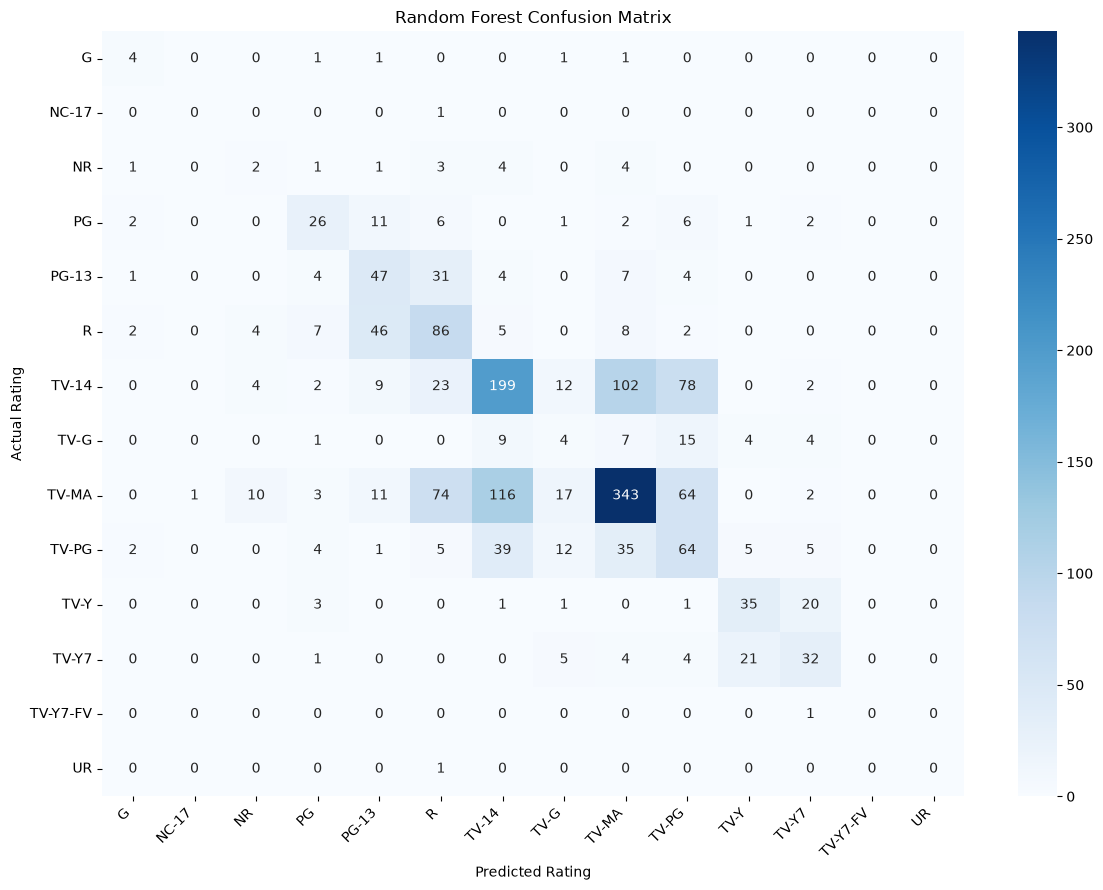

In [12]:
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

12. Train a second model

In [13]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")

Logistic Regression Accuracy: 0.2799


c:\Users\malaa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


13. Compare the models

In [14]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression"
    ],
    "Accuracy": [
        rf_accuracy,
        lr_accuracy
    ]
})

results

,Model,Accuracy
0,Random Forest,0.478953
1,Logistic Regression,0.279863


Visualize the comparison

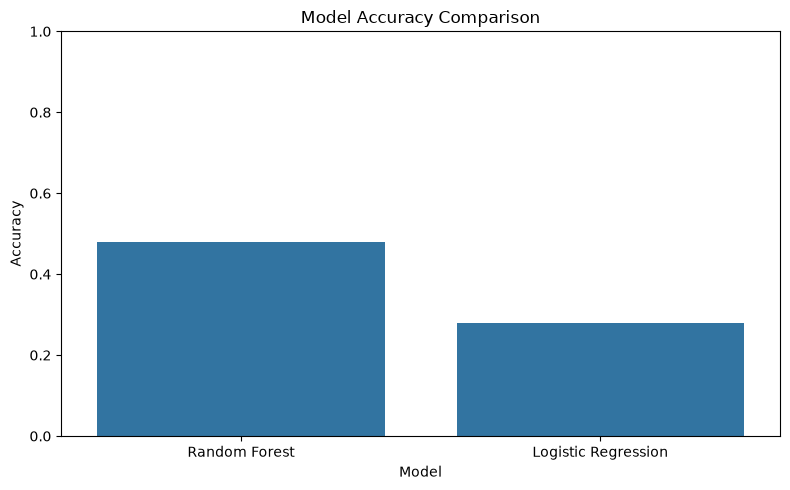

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()